In [2]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\Barış\Desktop\YAZILIM\tfidf-turkish-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
ds = load_dataset("maydogan/Turkish_SentimentAnalysis_TRSAv1")
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'score', 'review'],
        num_rows: 150000
    })
})

In [4]:
list(ds.keys())

['train']

In [5]:
split_name = next(iter(ds.keys()))
raw_df = ds[split_name].to_pandas()

In [6]:
raw_df.head(10)

,id,score,review
0,0,Positive,Kokusu çok güzel etkisi de efsane
1,1,Negative,hiç bir fark olmadı siyah nokta silmedi
2,2,Positive,şeffaf güzel bir krem elimi yumuşacık yaptı
3,3,Positive,Özellikle karma ve hassas cildiniz varsa La Ro...
4,4,Negative,çok iyi nemlendiriyor ama daha ucuz muadilleri...
5,5,Neutral,Ürün fena değil güzel tabi öbür kimyasallar gi...
6,6,Negative,şampuan çok köttü
7,7,Negative,Ürün kullanıp memnun olduğum bir ürün fakat şi...
8,8,Neutral,yeni kullaniyorum dokulmeleri azaltır inşallah
9,9,Positive,Kesinlikle saçlarınızda sarı işlem barsa hafta...


# 1ST PHASE

In [7]:
label_column = "score"
text_column = "review"

normalized_df = raw_df.copy()
normalized_df[text_column] = normalized_df[text_column].astype("string").str.strip()
review_label_counts = normalized_df.groupby(text_column)[label_column].nunique()
conflicting_texts = review_label_counts[review_label_counts.gt(1)].index
conflicting_reviews_df = normalized_df.loc[normalized_df[text_column].isin(conflicting_texts)].copy()

data_quality = pd.Series({
    "row_count": len(raw_df),
    "missing_text": raw_df[text_column].isna().sum(),
    "blank_text": normalized_df[text_column].eq("").sum(),
    "missing_label": raw_df[label_column].isna().sum(),
    "duplicate_review_rows": normalized_df.duplicated(subset=[text_column]).sum(),
    "duplicate_review_label_rows": normalized_df.duplicated(subset=[text_column, label_column]).sum(),
    "conflicting_review_groups": len(conflicting_texts),
    "conflicting_review_rows": normalized_df[text_column].isin(conflicting_texts).sum(),
    "whitespace_edges": raw_df[text_column].astype("string").ne(normalized_df[text_column]).sum()
})

data_quality

row_count                      150000
missing_text                        0
blank_text                          0
missing_label                       0
duplicate_review_rows            9046
duplicate_review_label_rows      8067
conflicting_review_groups         891
conflicting_review_rows          6883
whitespace_edges                  366
dtype: int64

In [8]:
conflicting_reviews_summary = pd.Series({
    "conflicting_text_groups": conflicting_reviews_df[text_column].nunique(),
    "conflicting_rows": len(conflicting_reviews_df),
    "unique_text_label_pairs": conflicting_reviews_df[[text_column, label_column]].drop_duplicates().shape[0]
})

conflicting_reviews_summary

conflicting_text_groups     891
conflicting_rows           6883
unique_text_label_pairs    1870
dtype: int64

In [9]:
label_counts = raw_df[label_column].value_counts(dropna=False)
label_counts

score
Positive    50000
Negative    50000
Neutral     50000
Name: count, dtype: int64

In [10]:
text_metrics_df = normalized_df.assign(
    character_count=normalized_df[text_column].str.len(),
    word_count=normalized_df[text_column].str.split().str.len()
)

text_metrics_df.groupby(label_column)[["character_count", "word_count"]].describe()

character_count                                                       \
                   count      mean        std  min   25%   50%    75%     max   
score                                                                           
Negative         50000.0  77.13818  69.703052  3.0  31.0  56.0  100.0  1458.0   
Neutral          50000.0  74.54372  70.029772  3.0  30.0  54.0   96.0  1993.0   
Positive         50000.0  92.91224  76.959919  5.0  45.0  71.0  117.0  1433.0   

         word_count                                                    
              count      mean        std  min  25%   50%   75%    max  
score                                                                  
Negative    50000.0  11.46540  10.114515  1.0  5.0   8.0  15.0  209.0  
Neutral     50000.0  10.99108   9.961529  1.0  5.0   8.0  14.0  283.0  
Positive    50000.0  13.36694  10.837566  1.0  7.0  10.0  17.0  207.0

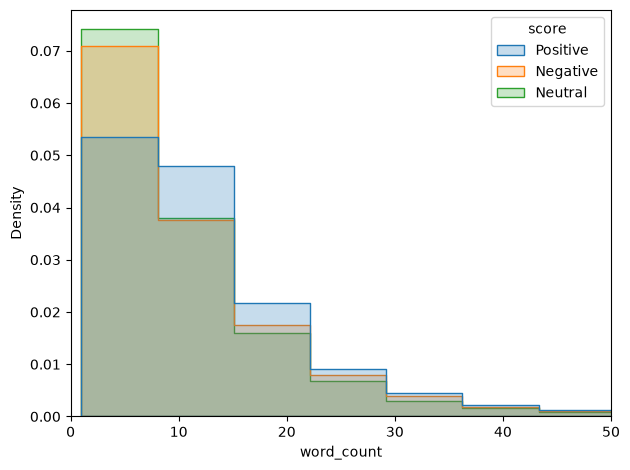

In [11]:
sns.histplot(
    data=text_metrics_df,
    x="word_count",
    hue=label_column,
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)
plt.xlim(0, text_metrics_df["word_count"].quantile(0.99))
plt.tight_layout()
plt.show()

In [12]:
conflicting_reviews_df.loc[
    :,
    [text_column, label_column]
].sort_values(text_column).head(20)

,review,score
26559,Abartıldığı kadar güzel olduğunu düşünmüyorum,Neutral
35836,Abartıldığı kadar güzel olduğunu düşünmüyorum,Negative
12967,Alınabilir,Neutral
43788,Alınabilir,Neutral
45899,Alınabilir,Negative
50358,Alınabilir,Neutral
58969,Alınabilir,Neutral
60016,Alınabilir,Neutral
73049,Alınabilir,Neutral
89950,Alınabilir,Neutral


In [13]:
cleaned_df = raw_df.dropna(subset=[text_column, label_column]).copy()
cleaned_df[text_column] = cleaned_df[text_column].astype("string").str.strip()
cleaned_df = cleaned_df.loc[cleaned_df[text_column].ne("")].copy()

cleaned_review_label_counts = cleaned_df.groupby(text_column)[label_column].nunique()
conflicting_texts = cleaned_review_label_counts[cleaned_review_label_counts.gt(1)].index
conflicting_rows_removed = len(conflicting_reviews_df)
cleaned_df = cleaned_df.loc[~cleaned_df[text_column].isin(conflicting_texts)].copy()

rows_before_deduplication = len(cleaned_df)
cleaned_df = cleaned_df.drop_duplicates(subset=[text_column, label_column]).reset_index(drop=True)
duplicate_rows_removed = rows_before_deduplication - len(cleaned_df)

cleaning_summary = pd.Series({
    "rows_before_cleaning": len(raw_df),
    "rows_after_cleaning": len(cleaned_df),
    "conflicting_text_groups_removed": len(conflicting_texts),
    "conflicting_rows_removed": conflicting_rows_removed,
    "duplicate_rows_removed": duplicate_rows_removed
})

cleaning_summary

rows_before_cleaning               150000
rows_after_cleaning                140063
conflicting_text_groups_removed       891
conflicting_rows_removed             6883
duplicate_rows_removed               3054
dtype: int64

In [14]:
cleaned_df[label_column].value_counts()

score
Positive    48240
Negative    46433
Neutral     45390
Name: count, dtype: int64

In [15]:
from sklearn.model_selection import train_test_split

train_df, temporary_df = train_test_split(
    cleaned_df,
    test_size=0.30,
    random_state=42,
    stratify=cleaned_df[label_column]

)

validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=42,
    stratify=temporary_df[label_column]
)

In [16]:
pd.DataFrame({
    "train": train_df[label_column].value_counts(normalize=True),
    "validation": validation_df[label_column].value_counts(normalize=True),
    "test": test_df[label_column].value_counts(normalize=True)
}).round(4)

,train,validation,test
score,,,
Positive,0.3444,0.3444,0.3444
Negative,0.3315,0.3315,0.3315
Neutral,0.3241,0.3241,0.3241


In [17]:
X_train = train_df[text_column]
y_train = train_df[label_column]
X_validation = validation_df[text_column]
y_validation = validation_df[label_column]

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

In [19]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Negative','Neutral','Positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


In [20]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
validation_predictions = baseline_model.predict(X_validation)
validation_report = classification_report(
    y_validation,
    validation_predictions,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(validation_report).transpose()

,precision,recall,f1-score,support
Negative,0.860123,0.822828,0.841063,6965.00000
Neutral,0.723927,0.713719,0.718787,6808.00000
Positive,0.819885,0.864981,0.841829,7236.00000
accuracy,0.801990,0.801990,0.801990,0.80199
macro avg,0.801312,0.800509,0.800560,21009.00000
weighted avg,0.802130,0.801990,0.801703,21009.00000


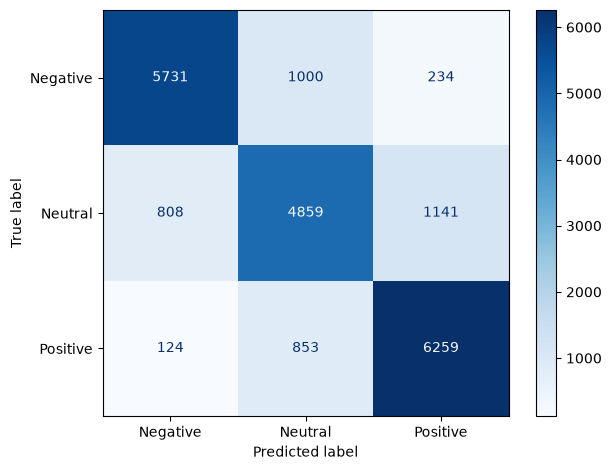

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    validation_predictions,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues"
)
plt.tight_layout()
plt.show()

In [22]:
from pathlib import Path
import joblib

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

model_directory = project_root / "models"
model_directory.mkdir(exist_ok=True)
model_path = model_directory / "tfidf_v0.1.joblib"
joblib.dump(baseline_model, model_path)
model_path

WindowsPath('c:/Users/Barış/Desktop/YAZILIM/tfidf-turkish-analysis/models/tfidf_v0.1.joblib')

# 2ND PHASE

In [23]:
from sklearn.pipeline import FeatureUnion

word_char_model = Pipeline([
    ("features", FeatureUnion([
        ("word_tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char_tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=300_000, sublinear_tf=True))
    ], n_jobs=1)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

In [24]:
word_char_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Negative','Neutral','Positive']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word_tfidf', ...), ('char_tfidf', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [25]:
word_char_validation_predictions = word_char_model.predict(X_validation)
word_char_validation_report = classification_report(y_validation, word_char_validation_predictions, output_dict=True, zero_division=0)
pd.DataFrame(word_char_validation_report).transpose()

,precision,recall,f1-score,support
Negative,0.859380,0.827423,0.843099,6965.000000
Neutral,0.726064,0.721798,0.723925,6808.000000
Positive,0.829330,0.863599,0.846117,7236.000000
accuracy,0.805655,0.805655,0.805655,0.805655
macro avg,0.804924,0.804273,0.804380,21009.000000
weighted avg,0.805829,0.805655,0.805520,21009.000000


In [26]:
validation_model_comparison = pd.DataFrame({
    "baseline_word_tfidf": {
        "accuracy": validation_report["accuracy"], 
        "macro_f1": validation_report["macro avg"]["f1-score"],
        "negative_f1": validation_report["Negative"]["f1-score"], 
        "neutral_f1": validation_report["Neutral"]["f1-score"], 
        "positive_f1": validation_report["Positive"]["f1-score"]},
    "word_plus_char_tfidf": {
            "accuracy": word_char_validation_report["accuracy"], 
            "macro_f1": word_char_validation_report["macro avg"]["f1-score"], 
            "negative_f1": word_char_validation_report["Negative"]["f1-score"], 
            "neutral_f1": word_char_validation_report["Neutral"]["f1-score"], 
            "positive_f1": word_char_validation_report["Positive"]["f1-score"]}
}).transpose()
validation_model_comparison

,accuracy,macro_f1,negative_f1,neutral_f1,positive_f1
baseline_word_tfidf,0.801990,0.80056,0.841063,0.718787,0.841829
word_plus_char_tfidf,0.805655,0.80438,0.843099,0.723925,0.846117


In [27]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
source_directory = project_root / "src"
if str(source_directory) not in sys.path:
    sys.path.insert(0, str(source_directory))

from emoji_features import extract_emoji_tokens

In [28]:
word_char_emoji_model = Pipeline([
    ("features", FeatureUnion([
        ("word_tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char_tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=300_000, sublinear_tf=True)),
        ("emoji_tfidf", TfidfVectorizer(
            tokenizer=extract_emoji_tokens, 
            token_pattern=None, 
            lowercase=False, 
            ngram_range=(1, 3), 
            min_df=2, 
            sublinear_tf=True))
    ], n_jobs=1)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

In [29]:
word_char_emoji_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Negative','Neutral','Positive']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word_tfidf', ...), ('char_tfidf', ...), ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [30]:
word_char_emoji_validation_predictions = word_char_emoji_model.predict(X_validation)
word_char_emoji_validation_report = classification_report(y_validation, word_char_emoji_validation_predictions, output_dict=True, zero_division=0)
pd.DataFrame(word_char_emoji_validation_report).transpose()

,precision,recall,f1-score,support
Negative,0.861061,0.829289,0.844877,6965.000000
Neutral,0.727219,0.723267,0.725237,6808.000000
Positive,0.831076,0.864842,0.847623,7236.000000
accuracy,0.807178,0.807178,0.807178,0.807178
macro avg,0.806452,0.805800,0.805912,21009.000000
weighted avg,0.807362,0.807178,0.807053,21009.000000


In [31]:
emoji_model_comparison = pd.DataFrame({
    "baseline_word_tfidf": {"accuracy": validation_report["accuracy"], "macro_f1": validation_report["macro avg"]["f1-score"], "negative_f1": validation_report["Negative"]["f1-score"], "neutral_f1": validation_report["Neutral"]["f1-score"], "positive_f1": validation_report["Positive"]["f1-score"]},
    "word_plus_char_tfidf": {"accuracy": word_char_validation_report["accuracy"], "macro_f1": word_char_validation_report["macro avg"]["f1-score"], "negative_f1": word_char_validation_report["Negative"]["f1-score"], "neutral_f1": word_char_validation_report["Neutral"]["f1-score"], "positive_f1": word_char_validation_report["Positive"]["f1-score"]},
    "word_char_emoji_tfidf": {"accuracy": word_char_emoji_validation_report["accuracy"], "macro_f1": word_char_emoji_validation_report["macro avg"]["f1-score"], "negative_f1": word_char_emoji_validation_report["Negative"]["f1-score"], "neutral_f1": word_char_emoji_validation_report["Neutral"]["f1-score"], "positive_f1": word_char_emoji_validation_report["Positive"]["f1-score"]}
}).transpose()
emoji_model_comparison

,accuracy,macro_f1,negative_f1,neutral_f1,positive_f1
baseline_word_tfidf,0.801990,0.800560,0.841063,0.718787,0.841829
word_plus_char_tfidf,0.805655,0.804380,0.843099,0.723925,0.846117
word_char_emoji_tfidf,0.807178,0.805912,0.844877,0.725237,0.847623


In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

search_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
base_parameters = {
    "classifier__C": [1.0],
    "features__word_tfidf__ngram_range": [(1, 2)],
    "features__word_tfidf__min_df": [2],
    "features__char_tfidf__ngram_range": [(3, 5)],
    "features__char_tfidf__min_df": [3],
    "features__emoji_tfidf__ngram_range": [(1, 3)],
    "features__emoji_tfidf__min_df": [2]
}

candidate_parameters = [
    base_parameters,
    {**base_parameters, "classifier__C": [0.5]},
    {**base_parameters, "classifier__C": [2.0]},
    {**base_parameters, "features__word_tfidf__ngram_range": [(1, 3)]},
    {**base_parameters, "features__word_tfidf__min_df": [3]},
    {**base_parameters, "features__char_tfidf__ngram_range": [(3, 7)], "features__char_tfidf__min_df": [5]},
    {**base_parameters, "features__emoji_tfidf__ngram_range": [(1, 2)]},
    {**base_parameters, "features__emoji_tfidf__min_df": [3]}
]

emoji_grid_search = GridSearchCV(
    estimator=word_char_emoji_model,
    param_grid=candidate_parameters,
    scoring="f1_macro",
    cv=search_cv,
    n_jobs=1,
    refit=True,
    verbose=2,
    return_train_score=False
)

In [33]:
emoji_grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END classifier__C=1.0, features__char_tfidf__min_df=3, features__char_tfidf__ngram_range=(3, 5), features__emoji_tfidf__min_df=2, features__emoji_tfidf__ngram_range=(1, 3), features__word_tfidf__min_df=2, features__word_tfidf__ngram_range=(1, 2); total time= 1.0min
[CV] END classifier__C=1.0, features__char_tfidf__min_df=3, features__char_tfidf__ngram_range=(3, 5), features__emoji_tfidf__min_df=2, features__emoji_tfidf__ngram_range=(1, 3), features__word_tfidf__min_df=2, features__word_tfidf__ngram_range=(1, 2); total time= 1.0min
[CV] END classifier__C=1.0, features__char_tfidf__min_df=3, features__char_tfidf__ngram_range=(3, 5), features__emoji_tfidf__min_df=2, features__emoji_tfidf__ngram_range=(1, 3), features__word_tfidf__min_df=2, features__word_tfidf__ngram_range=(1, 2); total time=  59.2s
[CV] END classifier__C=0.5, features__char_tfidf__min_df=3, features__char_tfidf__ngram_range=(3, 5), features__emoji_tfidf__mi

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'classifier__C': [1.0], 'features__char_tfidf__min_df': [3], 'features__char_tfidf__ngram_range': [(3, ...)], 'features__emoji_tfidf__min_df': [2], ...}, {'classifier__C': [0.5], 'features__char_tfidf__min_df': [3], 'features__char_tfidf__ngram_range': [(3, ...)], 'features__emoji_tfidf__min_df': [2], ...}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_``

In [34]:
cv_results_df = pd.DataFrame(emoji_grid_search.cv_results_)[
    [
        "param_classifier__C",
        "param_features__word_tfidf__ngram_range",
        "param_features__word_tfidf__min_df",
        "param_features__char_tfidf__ngram_range",
        "param_features__char_tfidf__min_df",
        "param_features__emoji_tfidf__ngram_range",
        "param_features__emoji_tfidf__min_df",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score").reset_index(drop=True)

cv_results_df

,param_classifier__C,param_features__word_tfidf__ngram_range,param_features__word_tfidf__min_df,param_features__char_tfidf__ngram_range,param_features__char_tfidf__min_df,param_features__emoji_tfidf__ngram_range,param_features__emoji_tfidf__min_df,mean_test_score,std_test_score,rank_test_score
0,1.0,"(1, 3)",2,"(3, 5)",3,"(1, 3)",2,0.805857,0.001135,1
1,0.5,"(1, 2)",2,"(3, 5)",3,"(1, 3)",2,0.805680,0.000498,2
2,1.0,"(1, 2)",2,"(3, 5)",3,"(1, 2)",2,0.805478,0.000271,3
3,1.0,"(1, 2)",2,"(3, 5)",3,"(1, 3)",2,0.805345,0.000332,4
4,1.0,"(1, 2)",2,"(3, 5)",3,"(1, 3)",3,0.805079,0.000602,5
5,1.0,"(1, 2)",2,"(3, 7)",5,"(1, 3)",2,0.804882,0.000232,6
6,1.0,"(1, 2)",3,"(3, 5)",3,"(1, 3)",2,0.804768,0.000618,7
7,2.0,"(1, 2)",2,"(3, 5)",3,"(1, 3)",2,0.801697,0.000835,8


In [35]:
tuned_model = emoji_grid_search.best_estimator_
tuned_validation_predictions = tuned_model.predict(X_validation)
tuned_validation_report = classification_report(
    y_validation,
    tuned_validation_predictions,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(tuned_validation_report).transpose()

,precision,recall,f1-score,support
Negative,0.862223,0.832017,0.846851,6965.000000
Neutral,0.730030,0.724882,0.727447,6808.000000
Positive,0.832226,0.865810,0.848686,7236.000000
accuracy,0.808939,0.808939,0.808939,0.808939
macro avg,0.808160,0.807570,0.807661,21009.000000
weighted avg,0.809054,0.808939,0.808790,21009.000000


In [36]:
validation_probabilities = tuned_model.predict_proba(X_validation)
validation_error_df = pd.DataFrame({
    "text": X_validation.reset_index(drop=True),
    "true_label": y_validation.reset_index(drop=True),
    "predicted_label": tuned_validation_predictions,
    "confidence": validation_probabilities.max(axis=1)
})
validation_error_df["is_error"] = validation_error_df["true_label"].ne(validation_error_df["predicted_label"])
validation_error_df["confidence"] = validation_error_df["confidence"].round(4)
validation_error_df.head()

,text,true_label,predicted_label,confidence,is_error
0,"Boyutu avuç içine sığacak kadar,titreşim yoğun...",Positive,Positive,0.5301,False
1,Saçımı uzatmadı kullanmaya devam ediyorum 2. K...,Neutral,Neutral,0.6149,False
2,Şeffaf farklı bir ürün geldi anlamadım kulland...,Negative,Negative,0.5521,False
3,Saçımı yumuşacık yapıyor çok seviyorum tavsiye...,Positive,Positive,0.9682,False
4,fiyatı çok iyi çok,Positive,Positive,0.7788,False


In [37]:
validation_error_df["is_error"].value_counts().rename(index={True: "Incorrect", False: "Correct"}).to_frame("count")

,count
is_error,
Correct,16995
Incorrect,4014


In [38]:
validation_confusion_counts = pd.crosstab(
    validation_error_df["true_label"],
    validation_error_df["predicted_label"],
    rownames=["True label"],
    colnames=["Predicted label"]
)
validation_confusion_counts

Predicted label,Negative,Neutral,Positive
True label,,,
Negative,5795,968,202
Neutral,812,4935,1061
Positive,114,857,6265


In [39]:
validation_error_pairs = (
    validation_error_df.loc[validation_error_df["is_error"]]
    .groupby(["true_label", "predicted_label"])
    .size()
    .sort_values(ascending=False)
    .rename("error_count")
    .reset_index()
)
validation_error_pairs

,true_label,predicted_label,error_count
0,Neutral,Positive,1061
1,Negative,Neutral,968
2,Positive,Neutral,857
3,Neutral,Negative,812
4,Negative,Positive,202
5,Positive,Negative,114


In [40]:
validation_error_examples = (
    validation_error_df.loc[validation_error_df["is_error"]]
    .sort_values(["true_label", "predicted_label", "confidence"], ascending=[True, True, False])
    .groupby(["true_label", "predicted_label"], group_keys=False)
    .head(5)
    .reset_index(drop=True)
)
validation_error_examples[["true_label", "predicted_label", "confidence", "text"]]

,true_label,predicted_label,confidence,text
0,Negative,Neutral,0.9868,fiyatına göre iyi fakat beğenemedm
1,Negative,Neutral,0.9813,rengi biraz açık ama güzel.
2,Negative,Neutral,0.9778,güzel🙂........
3,Negative,Neutral,0.9733,Rh işte orta seviye
4,Negative,Neutral,0.9731,İdare eder iyi
5,Negative,Positive,0.9934,kesinlikle harika bir takım 👍🏼 yumuşacık ve ka...
6,Negative,Positive,0.9912,çok güzel begendin harika bir ürün
7,Negative,Positive,0.9895,Gerçekten harika bir ürün. yorumlara bakarak...
8,Negative,Positive,0.9866,Fiyatı çok uygun. Çok beğendim. Saçları yumuşa...
9,Negative,Positive,0.9802,Bu fiyata harika oldu gerçekten bayıldım :)


In [41]:
(
    validation_error_df.loc[validation_error_df["is_error"]]
    .sort_values("confidence", ascending=True)
    .head(20)[["true_label", "predicted_label", "confidence", "text"]]
)

,true_label,predicted_label,confidence,text
18853,Positive,Negative,0.3366,Gerçekten yakıyo ama dayanılmayavak gibi değil...
18347,Neutral,Positive,0.3512,saçıma ilk kullanımda çok etki etmedi. bu para...
16695,Neutral,Positive,0.3523,"Mad tavsiyesiyle aldım, bir aydır düzenli kull..."
2269,Positive,Negative,0.3554,ürün güzel kaliteli hızlı kargo fakat o kadar ...
4085,Neutral,Negative,0.3565,Vakum cihazı etkili değil kuvvetli bir çekimi ...
20562,Negative,Neutral,0.3566,beğendim inanılmaz kendini salıyor ağzı yüzü b...
15481,Positive,Neutral,0.3566,sıkıntısız çok çabuk da geldi
3011,Negative,Neutral,0.3571,Ürün geldiğinds kırıktı biraz daha üzerine par...
6889,Negative,Neutral,0.3576,kisin c ok iyi baska biseye gerek kalmiyo
9485,Positive,Negative,0.3589,almanızı tavsiye ederim


In [42]:
validation_label_review = (
    validation_error_df.loc[validation_error_df["is_error"]]
    .sort_values(["true_label", "predicted_label", "confidence"], ascending=[True, True, False])
    .groupby(["true_label", "predicted_label"], group_keys=False)
    .head(10)
    .reset_index(drop=True)
)
validation_label_review["review_status"] = ""
validation_label_review["review_note"] = ""
validation_label_review[["true_label", "predicted_label", "confidence", "text", "review_status", "review_note"]]

,true_label,predicted_label,confidence,text,review_status,review_note
0,Negative,Neutral,0.9868,fiyatına göre iyi fakat beğenemedm,,
1,Negative,Neutral,0.9813,rengi biraz açık ama güzel.,,
2,Negative,Neutral,0.9778,güzel🙂........,,
3,Negative,Neutral,0.9733,Rh işte orta seviye,,
4,Negative,Neutral,0.9731,İdare eder iyi,,
5,Negative,Neutral,0.9701,Ürün güzel ama pek bir temizleyiciliğini görem...,,
6,Negative,Neutral,0.9692,Çok kaliteli değil ama iş görür. Uygun fiyatsa...,,
7,Negative,Neutral,0.9687,kokusu güzel ama kalıcı değil,,
8,Negative,Neutral,0.9657,normal bir ürün idare eder,,
9,Negative,Neutral,0.9628,Üründen çok emin olamadım sivilcelere iyi geld...,,


In [43]:
from sklearn.base import clone

balanced_model = clone(tuned_model)
balanced_model.set_params(classifier__class_weight="balanced")
balanced_model.fit(X_train, y_train)
balanced_validation_predictions = balanced_model.predict(X_validation)
balanced_validation_report = classification_report(
    y_validation,
    balanced_validation_predictions,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(balanced_validation_report).transpose()

,precision,recall,f1-score,support
Negative,0.863548,0.829576,0.846221,6965.000000
Neutral,0.724354,0.729142,0.726740,6808.000000
Positive,0.833758,0.860144,0.846745,7236.000000
accuracy,0.807559,0.807559,0.807559,0.807559
macro avg,0.807220,0.806287,0.806569,21009.000000
weighted avg,0.808182,0.807559,0.807684,21009.000000


In [44]:
class_weight_comparison = pd.DataFrame({
    "tuned_default": {
        "accuracy": tuned_validation_report["accuracy"],
        "macro_f1": tuned_validation_report["macro avg"]["f1-score"],
        "negative_f1": tuned_validation_report["Negative"]["f1-score"],
        "neutral_f1": tuned_validation_report["Neutral"]["f1-score"],
        "positive_f1": tuned_validation_report["Positive"]["f1-score"]
    },
    "class_weight_balanced": {
        "accuracy": balanced_validation_report["accuracy"],
        "macro_f1": balanced_validation_report["macro avg"]["f1-score"],
        "negative_f1": balanced_validation_report["Negative"]["f1-score"],
        "neutral_f1": balanced_validation_report["Neutral"]["f1-score"],
        "positive_f1": balanced_validation_report["Positive"]["f1-score"]
    }
}).transpose()
class_weight_comparison

,accuracy,macro_f1,negative_f1,neutral_f1,positive_f1
tuned_default,0.808939,0.807661,0.846851,0.727447,0.848686
class_weight_balanced,0.807559,0.806569,0.846221,0.726740,0.846745


In [45]:
tuned_model_comparison = pd.DataFrame({
    "emoji_default": {
        "accuracy": word_char_emoji_validation_report["accuracy"],
        "macro_f1": word_char_emoji_validation_report["macro avg"]["f1-score"],
        "negative_f1": word_char_emoji_validation_report["Negative"]["f1-score"],
        "neutral_f1": word_char_emoji_validation_report["Neutral"]["f1-score"],
        "positive_f1": word_char_emoji_validation_report["Positive"]["f1-score"]
    },
    "emoji_tuned": {
        "accuracy": tuned_validation_report["accuracy"],
        "macro_f1": tuned_validation_report["macro avg"]["f1-score"],
        "negative_f1": tuned_validation_report["Negative"]["f1-score"],
        "neutral_f1": tuned_validation_report["Neutral"]["f1-score"],
        "positive_f1": tuned_validation_report["Positive"]["f1-score"]
    }
}).transpose()

tuned_model_comparison

,accuracy,macro_f1,negative_f1,neutral_f1,positive_f1
emoji_default,0.807178,0.805912,0.844877,0.725237,0.847623
emoji_tuned,0.808939,0.807661,0.846851,0.727447,0.848686


In [79]:
emoji_grid_search.best_params_, emoji_grid_search.best_score_

({'classifier__C': 1.0,
  'features__char_tfidf__min_df': 3,
  'features__char_tfidf__ngram_range': (3, 5),
  'features__emoji_tfidf__min_df': 2,
  'features__emoji_tfidf__ngram_range': (1, 3),
  'features__word_tfidf__min_df': 2,
  'features__word_tfidf__ngram_range': (1, 3)},
 np.float64(0.8058574139712973))

In [81]:
from sklearn.base import clone

final_training_df = pd.concat([train_df, validation_df], ignore_index=True)
X_final_train = final_training_df[text_column]
y_final_train = final_training_df[label_column]

word_char_emoji_model_tuned = clone(emoji_grid_search.best_estimator_)
word_char_emoji_model_tuned.fit(X_final_train, y_final_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Negative','Neutral','Positive']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word_tfidf', ...), ('char_tfidf', ...), ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


### bu kısmın altına kod yazma

In [82]:
from pathlib import Path
import joblib

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

model_directory = project_root / "models"
model_directory.mkdir(exist_ok=True)
model_path = model_directory / "tfidf_v1.0.joblib"
joblib.dump(word_char_emoji_model_tuned, model_path)
model_path

WindowsPath('c:/Users/Barış/Desktop/YAZILIM/tfidf-turkish-analysis/models/tfidf_v1.0.joblib')